# Cryptocurrency Price Forecasting

## Prophet Model

### Objective

To build a Prophet time-series forecasting model using the preprocessed Bitcoin dataset and evaluate its performance on the unseen test period.

In [28]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
    r2_score
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [29]:
# Load cleaned dataset

df = pd.read_csv("../data/engineered_data_cleaned.csv")

print("Cleaned dataset loaded successfully.")
print("Dataset shape:", df.shape)

Cleaned dataset loaded successfully.
Dataset shape: (3011, 18)


In [30]:
# Prepare date column

df["Date"] = pd.to_datetime(df["Date"])

df = df.sort_values("Date").reset_index(drop=True)

print("Date column prepared successfully.")
print("First date:", df["Date"].min())
print("Last date:", df["Date"].max())

Date column prepared successfully.
First date: 2013-12-27 00:00:00
Last date: 2022-10-16 00:00:00


In [31]:
# Create chronological train-test split

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Training set:", train_df.shape)
print("Testing set:", test_df.shape)

print("\nTraining period:")
print(train_df["Date"].min(), "to", train_df["Date"].max())

print("\nTesting period:")
print(test_df["Date"].min(), "to", test_df["Date"].max())

Training set: (2408, 18)
Testing set: (603, 18)

Training period:
2013-12-27 00:00:00 to 2020-08-04 00:00:00

Testing period:
2020-08-05 00:00:00 to 2022-10-16 00:00:00


In [32]:
# Prepare Prophet training data

prophet_train = train_df[["Date", "Target"]].copy()

prophet_train = prophet_train.rename(
    columns={
        "Date": "ds",
        "Target": "y"
    }
)

print("Prophet training data:")
display(prophet_train.head())

Prophet training data:


,ds,y
0,2013-12-27,727.830017
1,2013-12-28,745.049988
2,2013-12-29,756.130005
3,2013-12-30,754.010010
4,2013-12-31,771.400024


In [35]:
# Create Prophet model

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

print("Prophet model created successfully.")

Prophet model created successfully.


In [36]:
# Train Prophet model

prophet_model.fit(prophet_train)

print("Prophet model trained successfully.")

19:16:12 - cmdstanpy - INFO - Chain [1] start processing
19:16:13 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully.


In [37]:
# Create future dates for forecasting

future = test_df[["Date"]].copy()

future = future.rename(
    columns={"Date": "ds"}
)

print("Future dates prepared successfully.")
print("Number of forecast dates:", len(future))
print("First forecast date:", future["ds"].min())
print("Last forecast date:", future["ds"].max())

Future dates prepared successfully.
Number of forecast dates: 603
First forecast date: 2020-08-05 00:00:00
Last forecast date: 2022-10-16 00:00:00


In [38]:
# Generate Prophet forecast

forecast = prophet_model.predict(future)

print("Forecast generated successfully.")
print("Forecast shape:", forecast.shape)

Forecast generated successfully.
Forecast shape: (603, 19)


In [39]:
# Prepare Prophet evaluation data

prophet_results = test_df[["Date", "Target"]].copy()

prophet_results = prophet_results.rename(
    columns={
        "Date": "ds",
        "Target": "actual"
    }
)

prophet_results["predicted"] = forecast["yhat"].values

print("Prophet evaluation data prepared successfully.")
display(prophet_results.head())

Prophet evaluation data prepared successfully.


,ds,actual,predicted
2408,2020-08-05,11779.773257,10437.386563
2409,2020-08-06,11601.472715,10452.546117
2410,2020-08-07,11754.045814,10463.877181
2411,2020-08-08,11675.739343,10451.259136
2412,2020-08-09,11878.111325,10468.299039


In [40]:
# Calculate Prophet evaluation metrics

mae = mean_absolute_error(
    prophet_results["actual"],
    prophet_results["predicted"]
)

rmse = np.sqrt(
    mean_squared_error(
        prophet_results["actual"],
        prophet_results["predicted"]
    )
)

r2 = r2_score(
    prophet_results["actual"],
    prophet_results["predicted"]
)

print("Prophet Model Performance")
print("-------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Prophet Model Performance
-------------------------
MAE : 25311.54466392193
RMSE: 29847.572687075328
R²  : -2.4875291927163032


In [41]:
# Create validation split

validation_split = int(len(prophet_train) * 0.80)

prophet_fit = prophet_train.iloc[:validation_split].copy()
prophet_validation = prophet_train.iloc[validation_split:].copy()

print("Prophet fitting data:", prophet_fit.shape)
print("Prophet validation data:", prophet_validation.shape)

print("\nFitting period:")
print(prophet_fit["ds"].min(), "to", prophet_fit["ds"].max())

print("\nValidation period:")
print(prophet_validation["ds"].min(), "to", prophet_validation["ds"].max())

Prophet fitting data: (1926, 2)
Prophet validation data: (482, 2)

Fitting period:
2013-12-27 00:00:00 to 2019-04-05 00:00:00

Validation period:
2019-04-06 00:00:00 to 2020-08-04 00:00:00


In [42]:
# Define Prophet configurations

prophet_configs = [
    {
        "changepoint_prior_scale": 0.01,
        "seasonality_mode": "additive"
    },
    {
        "changepoint_prior_scale": 0.05,
        "seasonality_mode": "additive"
    },
    {
        "changepoint_prior_scale": 0.10,
        "seasonality_mode": "additive"
    },
    {
        "changepoint_prior_scale": 0.20,
        "seasonality_mode": "multiplicative"
    },
    {
        "changepoint_prior_scale": 0.50,
        "seasonality_mode": "multiplicative"
    }
]

print("Number of configurations:", len(prophet_configs))

Number of configurations: 5


In [43]:
# Tune Prophet configurations

validation_results = []

for config in prophet_configs:

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=config["changepoint_prior_scale"],
        seasonality_mode=config["seasonality_mode"]
    )

    model.fit(prophet_fit)

    validation_forecast = model.predict(
        prophet_validation[["ds"]]
    )

    actual = prophet_validation["y"].values
    predicted = validation_forecast["yhat"].values

    validation_mae = mean_absolute_error(actual, predicted)

    validation_rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    validation_r2 = r2_score(actual, predicted)

    validation_results.append({
        "changepoint_prior_scale": config["changepoint_prior_scale"],
        "seasonality_mode": config["seasonality_mode"],
        "MAE": validation_mae,
        "RMSE": validation_rmse,
        "R2": validation_r2
    })

validation_results = pd.DataFrame(validation_results)

validation_results = validation_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(validation_results)

19:16:34 - cmdstanpy - INFO - Chain [1] start processing
19:16:34 - cmdstanpy - INFO - Chain [1] done processing
19:16:35 - cmdstanpy - INFO - Chain [1] start processing
19:16:35 - cmdstanpy - INFO - Chain [1] done processing
19:16:35 - cmdstanpy - INFO - Chain [1] start processing
19:16:36 - cmdstanpy - INFO - Chain [1] done processing
19:16:36 - cmdstanpy - INFO - Chain [1] start processing
19:16:39 - cmdstanpy - INFO - Chain [1] done processing
19:16:39 - cmdstanpy - INFO - Chain [1] start processing
19:16:42 - cmdstanpy - INFO - Chain [1] done processing


,changepoint_prior_scale,seasonality_mode,MAE,RMSE,R2
0,0.50,multiplicative,7283.121762,7687.059071,-21.073190
1,0.20,multiplicative,8030.261426,8436.655905,-25.587980
2,0.10,additive,8955.358864,9375.799570,-31.836836
3,0.05,additive,9780.040022,10233.336140,-38.118226
4,0.01,additive,9897.522017,10371.906232,-39.184802


In [44]:
# Define expanded Prophet configurations

prophet_configs_extended = [
    {
        "changepoint_prior_scale": 0.10,
        "n_changepoints": 50,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": False
    },
    {
        "changepoint_prior_scale": 0.50,
        "n_changepoints": 50,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": False
    },
    {
        "changepoint_prior_scale": 1.00,
        "n_changepoints": 50,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": False
    },
    {
        "changepoint_prior_scale": 0.50,
        "n_changepoints": 100,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": False
    },
    {
        "changepoint_prior_scale": 1.00,
        "n_changepoints": 100,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": False
    },
    {
        "changepoint_prior_scale": 0.50,
        "n_changepoints": 100,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": True
    },
    {
        "changepoint_prior_scale": 1.00,
        "n_changepoints": 100,
        "changepoint_range": 0.95,
        "seasonality_mode": "multiplicative",
        "log_transform": True
    }
]

print("Number of extended configurations:", len(prophet_configs_extended))

Number of extended configurations: 7


In [45]:
# Evaluate expanded Prophet configurations

extended_results = []

for config in prophet_configs_extended:

    fit_data = prophet_fit.copy()

    if config["log_transform"]:
        fit_data["y"] = np.log1p(fit_data["y"])

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=config["changepoint_prior_scale"],
        n_changepoints=config["n_changepoints"],
        changepoint_range=config["changepoint_range"],
        seasonality_mode=config["seasonality_mode"]
    )

    model.fit(fit_data)

    validation_forecast = model.predict(
        prophet_validation[["ds"]]
    )

    predicted = validation_forecast["yhat"].values

    if config["log_transform"]:
        predicted = np.expm1(predicted)

    actual = prophet_validation["y"].values

    validation_mae = mean_absolute_error(
        actual,
        predicted
    )

    validation_rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    validation_r2 = r2_score(
        actual,
        predicted
    )

    extended_results.append({
        "changepoint_prior_scale": config["changepoint_prior_scale"],
        "n_changepoints": config["n_changepoints"],
        "changepoint_range": config["changepoint_range"],
        "seasonality_mode": config["seasonality_mode"],
        "log_transform": config["log_transform"],
        "MAE": validation_mae,
        "RMSE": validation_rmse,
        "R2": validation_r2
    })

extended_results = pd.DataFrame(extended_results)

extended_results = extended_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(extended_results)

19:16:50 - cmdstanpy - INFO - Chain [1] start processing
19:16:52 - cmdstanpy - INFO - Chain [1] done processing
19:16:52 - cmdstanpy - INFO - Chain [1] start processing
19:16:55 - cmdstanpy - INFO - Chain [1] done processing
19:16:56 - cmdstanpy - INFO - Chain [1] start processing
19:16:59 - cmdstanpy - INFO - Chain [1] done processing
19:16:59 - cmdstanpy - INFO - Chain [1] start processing
19:17:03 - cmdstanpy - INFO - Chain [1] done processing
19:17:03 - cmdstanpy - INFO - Chain [1] start processing
19:17:07 - cmdstanpy - INFO - Chain [1] done processing
19:17:07 - cmdstanpy - INFO - Chain [1] start processing
19:17:10 - cmdstanpy - INFO - Chain [1] done processing
19:17:11 - cmdstanpy - INFO - Chain [1] start processing
19:17:14 - cmdstanpy - INFO - Chain [1] done processing


,changepoint_prior_scale,n_changepoints,changepoint_range,seasonality_mode,log_transform,MAE,RMSE,R2
0,0.5,100,0.95,multiplicative,False,6917.291765,8792.006069,-27.874909
1,1.0,100,0.95,multiplicative,False,7115.017303,9080.165565,-29.798687
2,0.1,50,0.95,multiplicative,False,7975.528768,10154.554648,-37.518240
3,0.5,50,0.95,multiplicative,False,11986.497331,15858.185581,-92.940239
4,1.0,50,0.95,multiplicative,False,14175.601006,19428.887828,-140.006961
5,0.5,100,0.95,multiplicative,True,65952.922567,111289.704489,-4625.522178
6,1.0,100,0.95,multiplicative,True,97247.000743,166394.548200,-10341.436322


In [46]:
# Test higher trend flexibility

prophet_configs_final = [
    {
        "changepoint_prior_scale": 1.0,
        "n_changepoints": 100
    },
    {
        "changepoint_prior_scale": 2.0,
        "n_changepoints": 100
    },
    {
        "changepoint_prior_scale": 5.0,
        "n_changepoints": 100
    },
    {
        "changepoint_prior_scale": 1.0,
        "n_changepoints": 200
    },
    {
        "changepoint_prior_scale": 2.0,
        "n_changepoints": 200
    }
]

print("Number of configurations:", len(prophet_configs_final))

Number of configurations: 5


In [47]:
# Evaluate higher trend flexibility

final_tuning_results = []

for config in prophet_configs_final:

    model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False,
        changepoint_prior_scale=config["changepoint_prior_scale"],
        n_changepoints=config["n_changepoints"],
        changepoint_range=0.95,
        seasonality_mode="multiplicative"
    )

    model.fit(prophet_fit)

    validation_forecast = model.predict(
        prophet_validation[["ds"]]
    )

    actual = prophet_validation["y"].values
    predicted = validation_forecast["yhat"].values

    validation_mae = mean_absolute_error(
        actual,
        predicted
    )

    validation_rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    validation_r2 = r2_score(
        actual,
        predicted
    )

    final_tuning_results.append({
        "changepoint_prior_scale": config["changepoint_prior_scale"],
        "n_changepoints": config["n_changepoints"],
        "MAE": validation_mae,
        "RMSE": validation_rmse,
        "R2": validation_r2
    })

final_tuning_results = pd.DataFrame(final_tuning_results)

final_tuning_results = final_tuning_results.sort_values(
    "RMSE"
).reset_index(drop=True)

display(final_tuning_results)

19:17:25 - cmdstanpy - INFO - Chain [1] start processing
19:17:29 - cmdstanpy - INFO - Chain [1] done processing
19:17:29 - cmdstanpy - INFO - Chain [1] start processing
19:17:33 - cmdstanpy - INFO - Chain [1] done processing
19:17:33 - cmdstanpy - INFO - Chain [1] start processing
19:17:37 - cmdstanpy - INFO - Chain [1] done processing
19:17:37 - cmdstanpy - INFO - Chain [1] start processing
19:17:43 - cmdstanpy - INFO - Chain [1] done processing
19:17:43 - cmdstanpy - INFO - Chain [1] start processing
19:17:49 - cmdstanpy - INFO - Chain [1] done processing


,changepoint_prior_scale,n_changepoints,MAE,RMSE,R2
0,1.0,100,7115.017303,9080.165565,-29.798687
1,2.0,100,7789.877820,9963.206410,-36.080273
2,1.0,200,8070.980922,10188.763468,-37.778199
3,2.0,200,8408.870135,10578.974894,-40.805348
4,5.0,100,8965.287118,11367.250362,-47.267580


In [48]:
# Train final Prophet model

final_prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.50,
    n_changepoints=100,
    changepoint_range=0.95,
    seasonality_mode="multiplicative"
)

final_prophet_model.fit(prophet_train)

print("Final Prophet model trained successfully.")

19:17:53 - cmdstanpy - INFO - Chain [1] start processing
19:17:58 - cmdstanpy - INFO - Chain [1] done processing


Final Prophet model trained successfully.


In [49]:
# Generate final test predictions

final_forecast = final_prophet_model.predict(
    test_df[["Date"]].rename(columns={"Date": "ds"})
)

print("Final test forecast generated successfully.")
print("Number of predictions:", len(final_forecast))

Final test forecast generated successfully.
Number of predictions: 603


In [50]:
# Calculate final Prophet test metrics

final_actual = test_df["Target"].values
final_predicted = final_forecast["yhat"].values

final_mae = mean_absolute_error(
    final_actual,
    final_predicted
)

final_rmse = np.sqrt(
    mean_squared_error(
        final_actual,
        final_predicted
    )
)

final_r2 = r2_score(
    final_actual,
    final_predicted
)

print("Final Prophet Test Performance")
print("------------------------------")
print("MAE :", final_mae)
print("RMSE:", final_rmse)
print("R²  :", final_r2)

Final Prophet Test Performance
------------------------------
MAE : 17502.628151523342
RMSE: 22269.510814092177
R²  : -0.9414274636927977


In [51]:
# Prepare Prophet data with regressors

prophet_features = [
    "Close",
    "Volume",
    "SMA_7",
    "SMA_14",
    "Volatility_7",
    "RSI_14",
    "MACD",
    "MACD_Signal",
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Volume_Change"
]

prophet_regressor_data = df[
    ["Date", "Target"] + prophet_features
].copy()

prophet_regressor_data = prophet_regressor_data.rename(
    columns={
        "Date": "ds",
        "Target": "y"
    }
)

print("Prophet regressor data prepared successfully.")
print("Shape:", prophet_regressor_data.shape)
print("Number of regressors:", len(prophet_features))

Prophet regressor data prepared successfully.
Shape: (3011, 14)
Number of regressors: 12


In [52]:
# Create chronological train validation test sets

split_index = int(len(prophet_regressor_data) * 0.80)

train_data = prophet_regressor_data.iloc[:split_index].copy()
test_data = prophet_regressor_data.iloc[split_index:].copy()

validation_split = int(len(train_data) * 0.80)

fit_data = train_data.iloc[:validation_split].copy()
validation_data = train_data.iloc[validation_split:].copy()

print("Fit data:", fit_data.shape)
print("Validation data:", validation_data.shape)
print("Test data:", test_data.shape)

print("\nFit period:")
print(fit_data["ds"].min(), "to", fit_data["ds"].max())

print("\nValidation period:")
print(validation_data["ds"].min(), "to", validation_data["ds"].max())

print("\nTest period:")
print(test_data["ds"].min(), "to", test_data["ds"].max())

Fit data: (1926, 14)
Validation data: (482, 14)
Test data: (603, 14)

Fit period:
2013-12-27 00:00:00 to 2019-04-05 00:00:00

Validation period:
2019-04-06 00:00:00 to 2020-08-04 00:00:00

Test period:
2020-08-05 00:00:00 to 2022-10-16 00:00:00


In [53]:
# Create Prophet model with regressors

prophet_regressor_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.5,
    n_changepoints=100,
    changepoint_range=0.95,
    seasonality_mode="multiplicative"
)

for feature in prophet_features:
    prophet_regressor_model.add_regressor(feature)

print("Prophet model with regressors created successfully.")

Prophet model with regressors created successfully.


In [54]:
# Train Prophet model with regressors

prophet_regressor_model.fit(fit_data)

print("Prophet regressor model trained successfully.")

19:18:24 - cmdstanpy - INFO - Chain [1] start processing
19:18:28 - cmdstanpy - INFO - Chain [1] done processing


Prophet regressor model trained successfully.


In [55]:
# Generate validation predictions

validation_forecast_reg = prophet_regressor_model.predict(
    validation_data[["ds"] + prophet_features]
)

print("Validation forecast generated successfully.")
print("Number of predictions:", len(validation_forecast_reg))

Validation forecast generated successfully.
Number of predictions: 482


In [56]:
# Evaluate Prophet model with regressors

validation_actual_reg = validation_data["y"].values
validation_predicted_reg = validation_forecast_reg["yhat"].values

reg_mae = mean_absolute_error(
    validation_actual_reg,
    validation_predicted_reg
)

reg_rmse = np.sqrt(
    mean_squared_error(
        validation_actual_reg,
        validation_predicted_reg
    )
)

reg_r2 = r2_score(
    validation_actual_reg,
    validation_predicted_reg
)

print("Prophet with Regressors - Validation Performance")
print("------------------------------------------------")
print("MAE :", reg_mae)
print("RMSE:", reg_rmse)
print("R²  :", reg_r2)

Prophet with Regressors - Validation Performance
------------------------------------------------
MAE : 2025.079236062989
RMSE: 2518.3413487204166
R²  : -1.3690480122701847


In [57]:
# Train final Prophet model with regressors

final_prophet_regressor_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    changepoint_prior_scale=0.5,
    n_changepoints=100,
    changepoint_range=0.95,
    seasonality_mode="multiplicative"
)

for feature in prophet_features:
    final_prophet_regressor_model.add_regressor(feature)

final_prophet_regressor_model.fit(train_data)

print("Final Prophet regressor model trained successfully.")

19:18:52 - cmdstanpy - INFO - Chain [1] start processing
19:18:55 - cmdstanpy - INFO - Chain [1] done processing


Final Prophet regressor model trained successfully.


In [58]:
# Generate final test predictions

final_reg_forecast = final_prophet_regressor_model.predict(
    test_data[["ds"] + prophet_features]
)

print("Final test predictions generated successfully.")
print("Number of predictions:", len(final_reg_forecast))

Final test predictions generated successfully.
Number of predictions: 603


In [59]:

# Calculate final Prophet regressor test metrics

final_reg_actual = test_data["y"].values
final_reg_predicted = final_reg_forecast["yhat"].values

final_reg_mae = mean_absolute_error(
    final_reg_actual,
    final_reg_predicted
)

final_reg_rmse = np.sqrt(
    mean_squared_error(
        final_reg_actual,
        final_reg_predicted
    )
)

final_reg_mape = mean_absolute_percentage_error(
    final_reg_actual,
    final_reg_predicted
) * 100

final_reg_r2 = r2_score(
    final_reg_actual,
    final_reg_predicted
)

print("Final Prophet with Regressors - Test Performance")
print("-----------------------------------------------")
print(f"MAE  : {final_reg_mae:.2f}")
print(f"RMSE : {final_reg_rmse:.2f}")
print(f"MAPE : {final_reg_mape:.2f}%")
print(f"R²   : {final_reg_r2:.4f}")

Final Prophet with Regressors - Test Performance
-----------------------------------------------
MAE  : 3466.04
RMSE : 4259.59
MAPE : 8.36%
R²   : 0.9290


In [60]:
# Prepare final Prophet results

final_prophet_results = test_data[["ds", "y"]].copy()

final_prophet_results["predicted"] = final_reg_forecast["yhat"].values

print("Final Prophet results prepared successfully.")
display(final_prophet_results.head())

Final Prophet results prepared successfully.


,ds,y,predicted
2408,2020-08-05,11779.773257,11706.094110
2409,2020-08-06,11601.472715,11785.019774
2410,2020-08-07,11754.045814,11593.546743
2411,2020-08-08,11675.739343,11704.641282
2412,2020-08-09,11878.111325,11674.176490


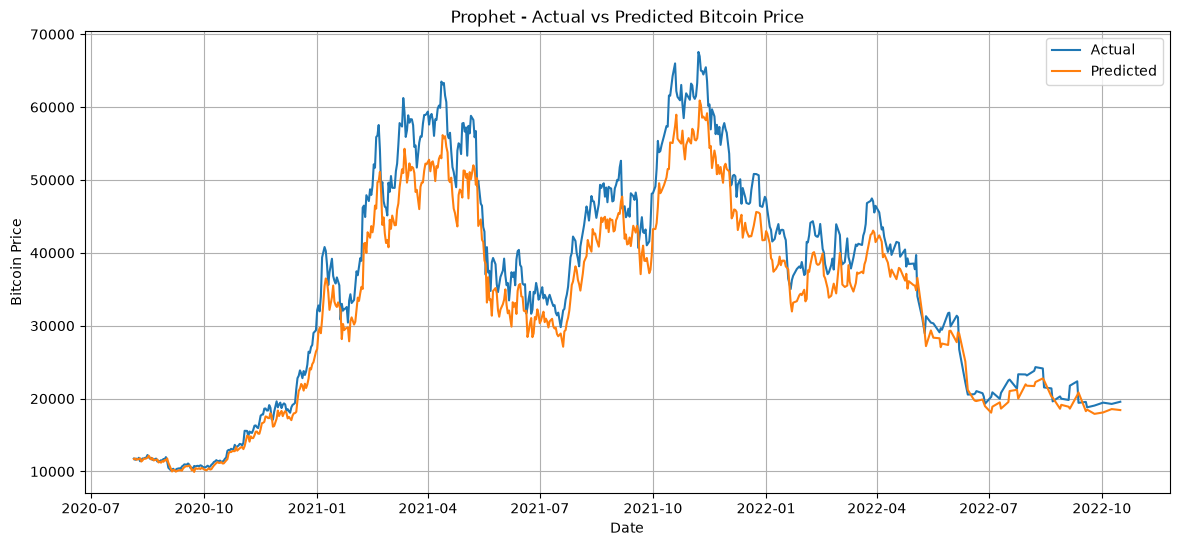

In [61]:
# Plot actual vs predicted values

plt.figure(figsize=(14, 6))

plt.plot(
    final_prophet_results["ds"],
    final_prophet_results["y"],
    label="Actual"
)

plt.plot(
    final_prophet_results["ds"],
    final_prophet_results["predicted"],
    label="Predicted"
)

plt.title("Prophet - Actual vs Predicted Bitcoin Price")
plt.xlabel("Date")
plt.ylabel("Bitcoin Price")
plt.legend()
plt.grid(True)

plt.savefig(
    "../outputs/graphs/10_prophet_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

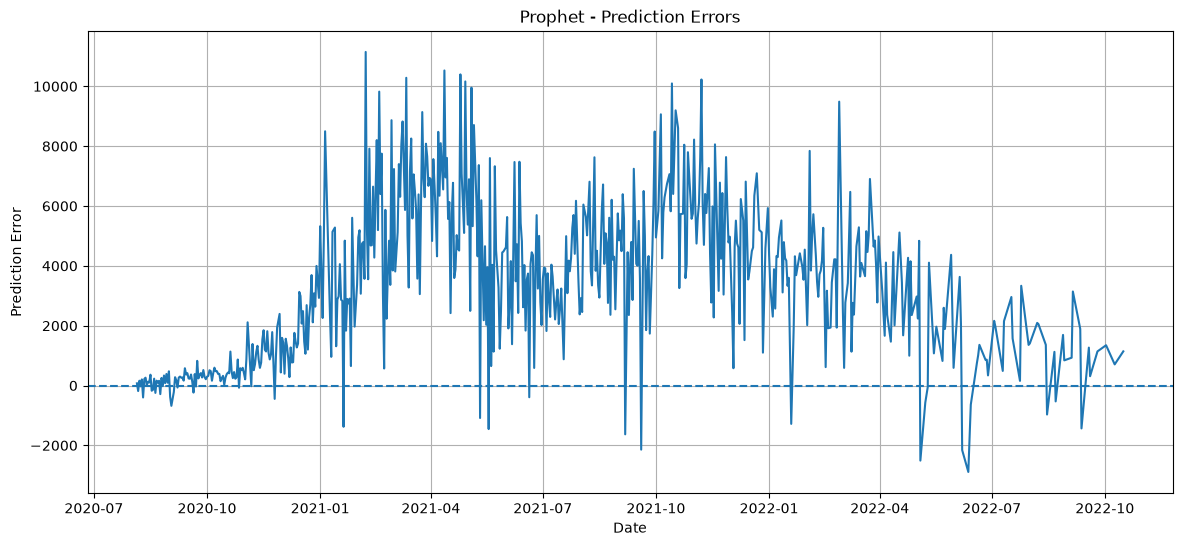

In [62]:
# Plot Prophet prediction errors

final_prophet_results["error"] = (
    final_prophet_results["y"]
    - final_prophet_results["predicted"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    final_prophet_results["ds"],
    final_prophet_results["error"]
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Prophet - Prediction Errors")
plt.xlabel("Date")
plt.ylabel("Prediction Error")
plt.grid(True)

plt.savefig(
    "../outputs/graphs/11_prophet_prediction_errors.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Prophet Model Summary

The Prophet model was developed and evaluated through multiple stages to identify an effective forecasting configuration.

### Modeling Process

- A baseline Prophet model was initially trained using the target price and date information.
- The baseline model was evaluated on the unseen test period using MAE, RMSE, MAPE, and R².
- Hyperparameter tuning was performed by testing different changepoint flexibility and seasonality configurations.
- The tuning results showed that the basic Prophet model had limited ability to capture cryptocurrency price movements.
- To improve the model, engineered market features were incorporated as additional Prophet regressors.
- The regressor-based Prophet model used 12 features, including price, volume, moving averages, volatility, RSI, MACD, lagged values, and volume change.
- The regressor-based model was evaluated on a validation period and showed a substantial improvement over the baseline Prophet model.
- The best configuration was then retrained using the complete training dataset.
- Final performance was evaluated on the completely unseen test period.

### Final Prophet Configuration

- Yearly seasonality: Enabled
- Weekly seasonality: Enabled
- Daily seasonality: Disabled
- Seasonality mode: Multiplicative
- Changepoint prior scale: 0.5
- Number of changepoints: 100
- Changepoint range: 0.95
- Engineered regressors: 12

### Final Test Performance

| Metric | Value |
|---|---:|
| MAE | 3466.04 |
| RMSE | 4259.59 |
| MAPE | 8.36% |
| R² | 0.92897 |

### Conclusion

The final Prophet model with engineered regressors substantially outperformed the initial Prophet model. The inclusion of technical indicators, lagged features, price information, and trading volume allowed Prophet to capture cryptocurrency price movements more effectively.

The final model achieved an R² of approximately 0.929 on the unseen test period, explaining approximately 92.9% of the variance in the target values. It achieved a Mean Absolute Percentage Error (MAPE) of 8.36%, indicating an average absolute prediction error of approximately 8.36% relative to the actual target values. The Actual vs Predicted plot shows that the model follows the overall movement of Bitcoin prices, although larger errors occur during periods of rapid price changes.

In [63]:
# Save final Prophet results

final_prophet_results.to_csv(
    "../outputs/prophet_final_results.csv",
    index=False
)

print("Final Prophet results saved successfully.")
print("Saved to: ../outputs/prophet_final_results.csv")

Final Prophet results saved successfully.
Saved to: ../outputs/prophet_final_results.csv


In [64]:
# Save final Prophet model

import pickle

model_path = "../models/prophet_regressor_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(final_prophet_regressor_model, file)

print("Final Prophet model saved successfully.")
print("Model path:", model_path)

Final Prophet model saved successfully.
Model path: ../models/prophet_regressor_model.pkl
